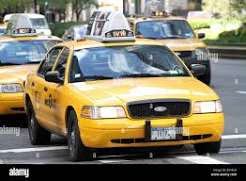

In [1]:
#Load the parquet file

import pandas as pd
df=pd.read_parquet(r'C:\Users\USER\Downloads\yellow_tripdata_2025-01.parquet')

In [2]:
#Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load and inspect the dataset

In [5]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [17]:
df.tail()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
3475221,2,2025-01-31 23:01:48,2025-01-31 23:16:29,NaN,3.35,NaN,None,79,237,0,15.85,0.0,0.5,0.0,0.0,1.0,20.60,NaN,NaN,0.75
3475222,2,2025-01-31 23:50:29,2025-02-01 00:17:27,NaN,8.73,NaN,None,161,116,0,28.14,0.0,0.5,0.0,0.0,1.0,32.89,NaN,NaN,0.75
3475223,2,2025-01-31 23:26:59,2025-01-31 23:43:01,NaN,2.64,NaN,None,144,246,0,14.91,0.0,0.5,0.0,0.0,1.0,19.66,NaN,NaN,0.75
3475224,2,2025-01-31 23:14:34,2025-01-31 23:34:52,NaN,3.16,NaN,None,142,107,0,17.55,0.0,0.5,0.0,0.0,1.0,22.30,NaN,NaN,0.75
3475225,2,2025-01-31 23:56:42,2025-02-01 00:07:27,NaN,2.29,NaN,None,237,238,0,12.09,0.0,0.5,0.0,0.0,1.0,16.09,NaN,NaN,0.00


In [18]:
print("Number of rows:", df.shape[0])

Number of rows: 3475226


In [19]:
print("Number of columns:", df.shape[1])

Number of columns: 20


In [20]:
print("Dataset shape:", df.shape)

Dataset shape: (3475226, 20)


In [21]:
print(df.columns.tolist())

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']


In [22]:
df.dtypes

,0
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,object
PULocationID,int32
DOLocationID,int32
payment_type,int64


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

# Unique Values

In [26]:
unique_counts = df.nunique().sort_values(ascending=False)
unique_counts

,0
tpep_pickup_datetime,1672077
tpep_dropoff_datetime,1671993
total_amount,21995
fare_amount,11538
trip_distance,4545
tip_amount,4197
tolls_amount,1234
PULocationID,261
DOLocationID,260
extra,77


# Missing-Value Analysis

In [8]:
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})
missing_summary.sort_values('Missing Percentage',ascending=False)

,Missing Values,Missing Percentage
passenger_count,540149,15.542845
congestion_surcharge,540149,15.542845
store_and_fwd_flag,540149,15.542845
RatecodeID,540149,15.542845
Airport_fee,540149,15.542845
tpep_dropoff_datetime,0,0.000000
VendorID,0,0.000000
tpep_pickup_datetime,0,0.000000
DOLocationID,0,0.000000
payment_type,0,0.000000


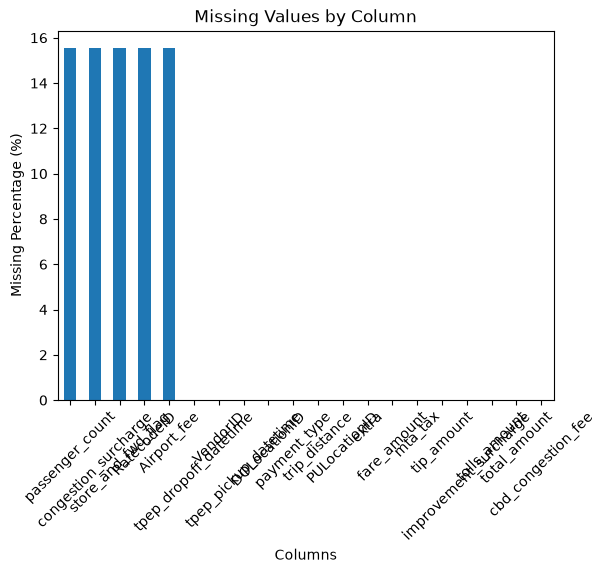

In [9]:
missing_percentage.sort_values(ascending=False).plot(kind='bar')
plt.title('Missing Values by Column')
plt.xlabel('Columns')
plt.ylabel('Missing Percentage (%)')
plt.xticks(rotation=45)
plt.show()

# Duplicate-Value Analysis

In [10]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [11]:
duplicate_percentage = (duplicate_count / len(df)) * 100
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 0.00%


# Datetime Validation

In [12]:
print(df['tpep_pickup_datetime'].dtype)
print(df['tpep_dropoff_datetime'].dtype)

datetime64[us]
datetime64[us]


In [13]:
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'],errors='coerce')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'],errors='coerce')

In [14]:
print(df[['tpep_pickup_datetime','tpep_dropoff_datetime']].dtypes)

tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
dtype: object


# Investigate Passenger Count

In [15]:
print(df['passenger_count'].value_counts(dropna=False).sort_index())

passenger_count
0.0      24656
1.0    2322434
2.0     407761
3.0      91409
4.0      59009
5.0      17786
6.0      12004
7.0          4
8.0         11
9.0          3
NaN     540149
Name: count, dtype: int64


In [16]:
invalid_passenger = df[(df['passenger_count'] <= 0) |(df['passenger_count'].isna())]
print("Potentially invalid passenger records:",len(invalid_passenger))

Potentially invalid passenger records: 564805


# Investigate Passenger Count

In [17]:
print(df['passenger_count'].value_counts(dropna=False).sort_index())

passenger_count
0.0      24656
1.0    2322434
2.0     407761
3.0      91409
4.0      59009
5.0      17786
6.0      12004
7.0          4
8.0         11
9.0          3
NaN     540149
Name: count, dtype: int64


In [18]:
invalid_passenger = df[(df['passenger_count'] <= 0) |(df['passenger_count'].isna())]
print("Potentially invalid passenger records:",len(invalid_passenger))

Potentially invalid passenger records: 564805


# Investigate Trip Distance

In [19]:
df['trip_distance'].describe()

count    3.475226e+06
mean     5.855126e+00
std      5.646016e+02
min      0.000000e+00
25%      9.800000e-01
50%      1.670000e+00
75%      3.100000e+00
max      2.764236e+05
Name: trip_distance, dtype: float64

In [20]:
invalid_distance = df[df['trip_distance'] <= 0]
print("Zero/negative distance records:",len(invalid_distance))

Zero/negative distance records: 90893


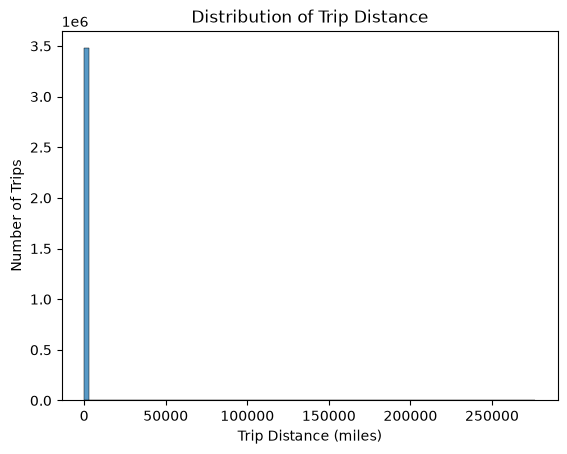

In [21]:
sns.histplot(df['trip_distance'],bins=100)
plt.title('Distribution of Trip Distance')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Number of Trips')
plt.show()

# Create Cleaned DataFrame

In [22]:
clean_df = df.copy()
print(clean_df.shape)

(3475226, 20)


In [23]:
clean_df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.00,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.10,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.10,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.20,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.80,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3475221,2,2025-01-31 23:01:48,2025-01-31 23:16:29,NaN,3.35,NaN,NaN,79,237,0,15.85,0.0,0.5,0.00,0.0,1.0,20.60,NaN,NaN,0.75
3475222,2,2025-01-31 23:50:29,2025-02-01 00:17:27,NaN,8.73,NaN,NaN,161,116,0,28.14,0.0,0.5,0.00,0.0,1.0,32.89,NaN,NaN,0.75
3475223,2,2025-01-31 23:26:59,2025-01-31 23:43:01,NaN,2.64,NaN,NaN,144,246,0,14.91,0.0,0.5,0.00,0.0,1.0,19.66,NaN,NaN,0.75
3475224,2,2025-01-31 23:14:34,2025-01-31 23:34:52,NaN,3.16,NaN,NaN,142,107,0,17.55,0.0,0.5,0.00,0.0,1.0,22.30,NaN,NaN,0.75


# Create Trip Duration

In [24]:
clean_df['trip_duration_minutes'] = (clean_df['tpep_dropoff_datetime'] - clean_df['tpep_pickup_datetime']).dt.total_seconds() / 60

In [25]:
clean_df['trip_duration_minutes'].describe()

count    3.475226e+06
mean     1.501812e+01
std      3.871358e+01
min     -5.147232e+04
25%      7.283333e+00
50%      1.170000e+01
75%      1.833333e+01
max      5.626317e+03
Name: trip_duration_minutes, dtype: float64

# Check Impossible Durations

In [26]:
invalid_time = clean_df[clean_df['trip_duration_minutes'] < 0]
print("Drop-off before pickup:",len(invalid_time))

Drop-off before pickup: 124


In [27]:
zero_duration = clean_df[clean_df['trip_duration_minutes'] == 0]
print("Zero-duration trips:",len(zero_duration))

Zero-duration trips: 1927


In [28]:
clean_df['trip_duration_minutes'].quantile([0.90, 0.95, 0.99, 0.999])

0.900    27.550000
0.950    36.200000
0.990    58.916667
0.999    98.262917
Name: trip_duration_minutes, dtype: float64

# Create Required Datetime Features

In [29]:
clean_df['pickup_date'] = (clean_df['tpep_pickup_datetime'].dt.date)
clean_df['pickup_hour'] = (clean_df['tpep_pickup_datetime'].dt.hour)
clean_df['day_of_week'] = (clean_df['tpep_pickup_datetime'].dt.day_name())
clean_df['is_weekend'] = (clean_df['tpep_pickup_datetime'].dt.dayofweek >= 5)

In [30]:
clean_df[['tpep_pickup_datetime',
        'pickup_date',
        'pickup_hour',
        'day_of_week',
        'is_weekend']].head()

,tpep_pickup_datetime,pickup_date,pickup_hour,day_of_week,is_weekend
0,2025-01-01 00:18:38,2025-01-01,0,Wednesday,False
1,2025-01-01 00:32:40,2025-01-01,0,Wednesday,False
2,2025-01-01 00:44:04,2025-01-01,0,Wednesday,False
3,2025-01-01 00:14:27,2025-01-01,0,Wednesday,False
4,2025-01-01 00:21:34,2025-01-01,0,Wednesday,False


# Create Average Speed

In [31]:
clean_df['average_speed_mph'] = np.where(clean_df['trip_duration_minutes'] > 0,clean_df['trip_distance'] /(clean_df['trip_duration_minutes'] / 60),np.nan)

In [32]:
clean_df['average_speed_mph'].describe()

count    3.473175e+06
mean     2.573553e+01
std      3.873889e+03
min      0.000000e+00
25%      7.209011e+00
50%      9.517748e+00
75%      1.293292e+01
max      3.722497e+06
Name: average_speed_mph, dtype: float64

# Create Distance Categories

In [33]:
def distance_category(distance):
    if distance < 2:
        return 'Short'
    elif distance < 5:
        return 'Medium'
    else:
        return 'Long'

clean_df['distance_category'] = (clean_df['trip_distance'].apply(distance_category))

In [34]:
clean_df['distance_category'].value_counts()

distance_category
Short     2026110
Medium     923231
Long       525885
Name: count, dtype: int64

# Create Duration Categories

In [35]:
def duration_category(duration):
    if duration < 10:
        return 'Very Short'
    elif duration < 20:
        return 'Short'
    elif duration < 40:
        return 'Medium'
    else:
        return 'Long'
clean_df['duration_category'] = (clean_df['trip_duration_minutes'].apply(duration_category))

# Create Route

In [36]:
clean_df['route'] = (clean_df['PULocationID'].astype(str)+ ' → ' +clean_df['DOLocationID'].astype(str))

# Data Cleaning

In [37]:
clean_df = clean_df[clean_df['tpep_pickup_datetime'].notna() & clean_df['tpep_dropoff_datetime'].notna()].copy()

In [38]:
clean_df = clean_df[clean_df['trip_duration_minutes'] > 0].copy()

# NumPy Statistical Analysis

In [39]:
def numpy_statistics(series):
    values = series.dropna().to_numpy()
    return {
        'Mean': np.mean(values),
        'Median': np.median(values),
        'Minimum': np.min(values),
        'Maximum': np.max(values),
        'Variance': np.var(values),
        'Standard Deviation': np.std(values),
        '25th Percentile': np.percentile(values, 25),
        '50th Percentile': np.percentile(values, 50),
        '75th Percentile': np.percentile(values, 75),
        '90th Percentile': np.percentile(values, 90),
        '95th Percentile': np.percentile(values, 95),
        '99th Percentile': np.percentile(values, 99)
    }

In [40]:
numpy_statistics(clean_df['trip_distance'])

{'Mean': np.float64(5.857639600653581),
 'Median': np.float64(1.67),
 'Minimum': np.float64(0.0),
 'Maximum': np.float64(276423.57),
 'Variance': np.float64(318963.10404770955),
 'Standard Deviation': np.float64(564.7681861150728),
 '25th Percentile': np.float64(0.98),
 '50th Percentile': np.float64(1.67),
 '75th Percentile': np.float64(3.1),
 '90th Percentile': np.float64(7.7),
 '95th Percentile': np.float64(11.83),
 '99th Percentile': np.float64(19.51)}

In [41]:
numpy_statistics(
    clean_df['trip_duration_minutes']
)

{'Mean': np.float64(15.041875263027825),
 'Median': np.float64(11.7),
 'Minimum': np.float64(0.016666666666666666),
 'Maximum': np.float64(5626.316666666667),
 'Variance': np.float64(736.2246405638849),
 'Standard Deviation': np.float64(27.133459797156075),
 '25th Percentile': np.float64(7.283333333333333),
 '50th Percentile': np.float64(11.7),
 '75th Percentile': np.float64(18.35),
 '90th Percentile': np.float64(27.55),
 '95th Percentile': np.float64(36.21666666666667),
 '99th Percentile': np.float64(58.916666666666664)}

In [42]:
numpy_statistics(
    clean_df['passenger_count']
)

{'Mean': np.float64(1.297966586493798),
 'Median': np.float64(1.0),
 'Minimum': np.float64(0.0),
 'Maximum': np.float64(9.0),
 'Variance': np.float64(0.5636568107011662),
 'Standard Deviation': np.float64(0.7507708110343437),
 '25th Percentile': np.float64(1.0),
 '50th Percentile': np.float64(1.0),
 '75th Percentile': np.float64(1.0),
 '90th Percentile': np.float64(2.0),
 '95th Percentile': np.float64(3.0),
 '99th Percentile': np.float64(5.0)}

In [43]:
numpy_statistics(
    clean_df['average_speed_mph']
)

{'Mean': np.float64(25.735527214781545),
 'Median': np.float64(9.517747858017136),
 'Minimum': np.float64(0.0),
 'Maximum': np.float64(3722496.9),
 'Variance': np.float64(15007009.497824455),
 'Standard Deviation': np.float64(3873.888162792578),
 '25th Percentile': np.float64(7.2090112640801),
 '50th Percentile': np.float64(9.517747858017136),
 '75th Percentile': np.float64(12.93291536050157),
 '90th Percentile': np.float64(19.436619718309856),
 '95th Percentile': np.float64(25.06782459959569),
 '99th Percentile': np.float64(35.5422930939341)}

# IQR Outlier Analysis

In [44]:
def iqr_analysis(series):
    values = series.dropna()
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)]
    return {
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers)
    }

In [45]:
iqr_analysis(clean_df['trip_distance'])

{'Q1': np.float64(0.98),
 'Q3': np.float64(3.1),
 'IQR': np.float64(2.12),
 'Lower Bound': np.float64(-2.2),
 'Upper Bound': np.float64(6.28),
 'Outlier Count': 422331}

In [46]:
iqr_analysis(clean_df['trip_duration_minutes'])

{'Q1': np.float64(7.283333333333333),
 'Q3': np.float64(18.35),
 'IQR': np.float64(11.066666666666668),
 'Lower Bound': np.float64(-9.316666666666668),
 'Upper Bound': np.float64(34.95),
 'Outlier Count': 190298}

In [47]:
iqr_analysis(clean_df['average_speed_mph'])

{'Q1': np.float64(7.2090112640801),
 'Q3': np.float64(12.93291536050157),
 'IQR': np.float64(5.723904096421469),
 'Lower Bound': np.float64(-1.3768448805521025),
 'Upper Bound': np.float64(21.51877150513377),
 'Outlier Count': 270262}

# Time Analysis

In [48]:
trips_by_hour = (clean_df.groupby('pickup_hour').size())
trips_by_hour

pickup_hour
0      93382
1      64461
2      43907
3      28483
4      20021
5      22540
6      50007
7     102515
8     141196
9     142769
10    148208
11    159994
12    175319
13    186027
14    202185
15    213544
16    216908
17    253347
18    267771
19    220921
20    194896
21    205882
22    182138
23    136754
dtype: int64

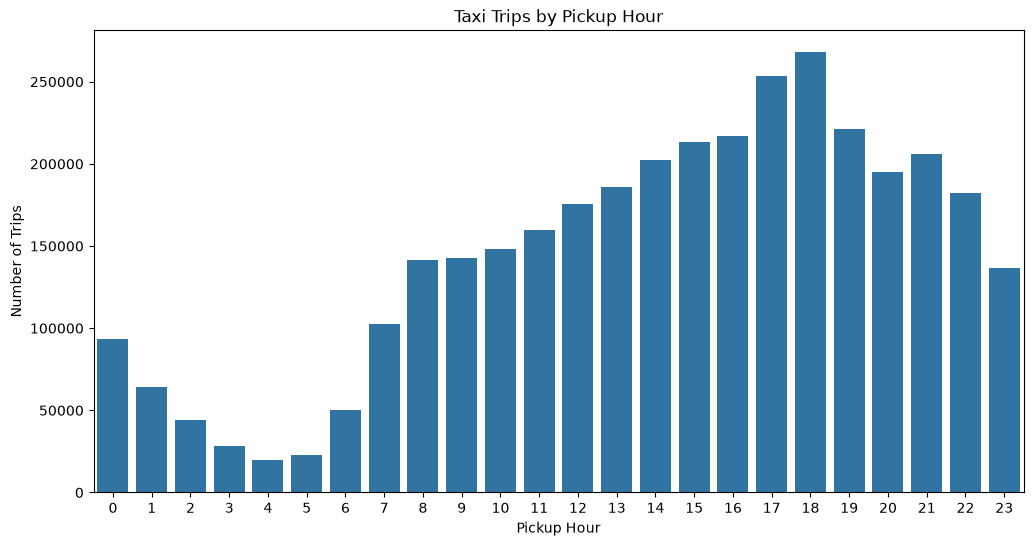

In [49]:
plt.figure(figsize=(12, 6))
sns.barplot(x=trips_by_hour.index,y=trips_by_hour.values)
plt.title('Taxi Trips by Pickup Hour')
plt.xlabel('Pickup Hour')
plt.ylabel('Number of Trips')
plt.show()

In [50]:
busiest_hour = trips_by_hour.idxmax()
lowest_hour = trips_by_hour.idxmin()
print("Busiest hour:", busiest_hour)
print("Lowest activity hour:", lowest_hour)

Busiest hour: 18
Lowest activity hour: 4


# Trips By Day

In [51]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday']
trips_by_day = (clean_df['day_of_week'].value_counts().reindex(day_order))
trips_by_day

day_of_week
Monday       363584
Tuesday      453714
Wednesday    577000
Thursday     613848
Friday       586426
Saturday     476208
Sunday       402395
Name: count, dtype: int64

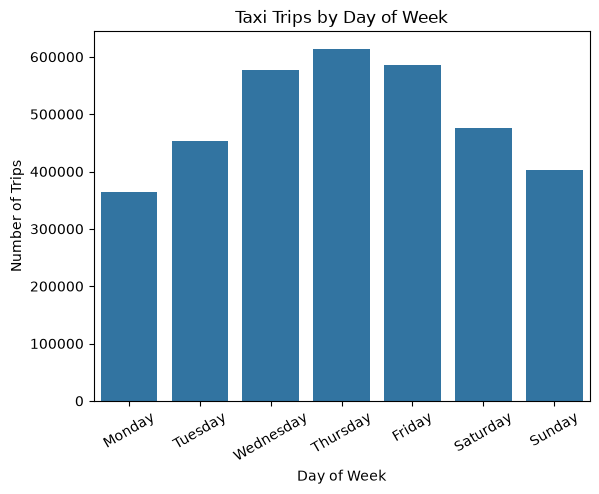

In [52]:
sns.barplot(x=trips_by_day.index,y=trips_by_day.values)
plt.title('Taxi Trips by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=30)
plt.show()

# Weekday vs Weekend

In [53]:
weekday_weekend = (clean_df['is_weekend'].map({False: 'Weekday',True: 'Weekend'}).value_counts())
weekday_weekend

is_weekend
Weekday    2594572
Weekend     878603
Name: count, dtype: int64

In [54]:
weekday_weekend_percentage = (weekday_weekend /weekday_weekend.sum() * 100)
weekday_weekend_percentage

is_weekend
Weekday    74.703175
Weekend    25.296825
Name: count, dtype: float64

# Hour × Day Heatmap

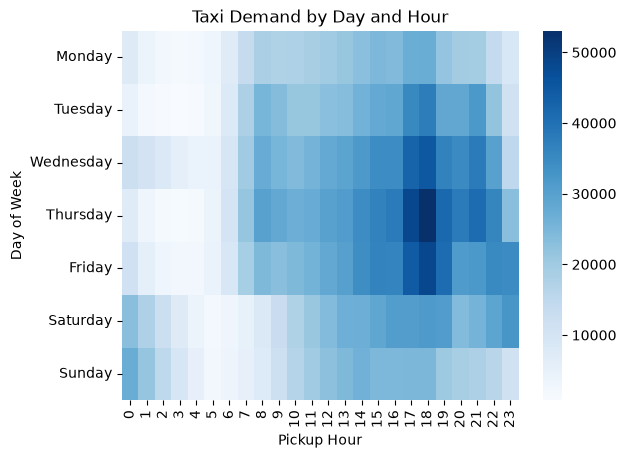

In [55]:
hour_day = pd.crosstab(clean_df['day_of_week'],clean_df['pickup_hour'])
hour_day = hour_day.reindex(day_order)
sns.heatmap(hour_day,cmap='Blues')
plt.title('Taxi Demand by Day and Hour')
plt.xlabel('Pickup Hour')
plt.ylabel('Day of Week')
plt.show()

# Average Duration By Hour

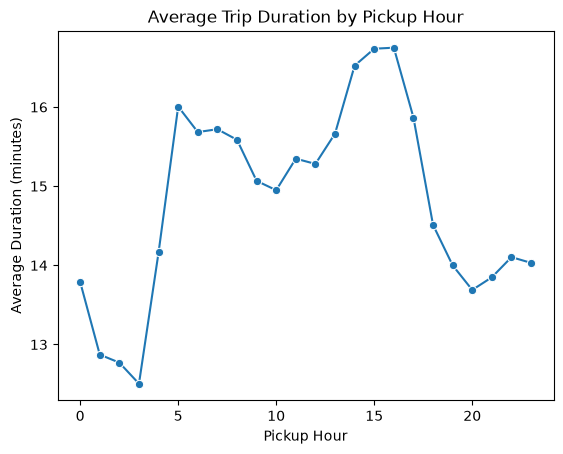

In [56]:
avg_duration_hour = (clean_df.groupby('pickup_hour')['trip_duration_minutes'].mean())
sns.lineplot(x=avg_duration_hour.index,y=avg_duration_hour.values,marker='o')
plt.title('Average Trip Duration by Pickup Hour')
plt.xlabel('Pickup Hour')
plt.ylabel('Average Duration (minutes)')
plt.show()

# Average Distance By Hour

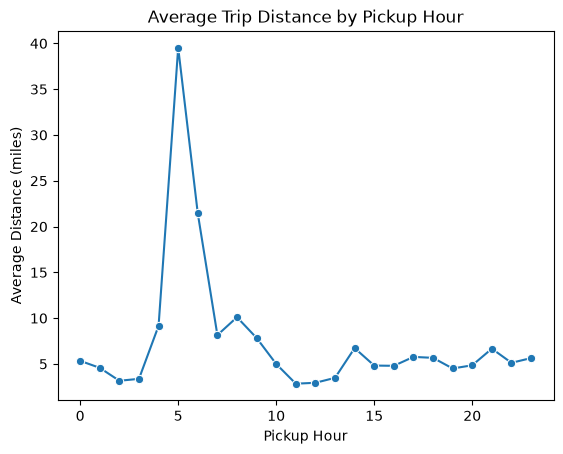

In [57]:
avg_distance_hour = (clean_df.groupby('pickup_hour')['trip_distance'].mean())
sns.lineplot(x=avg_distance_hour.index,y=avg_distance_hour.values,marker='o')
plt.title('Average Trip Distance by Pickup Hour')
plt.xlabel('Pickup Hour')
plt.ylabel('Average Distance (miles)')
plt.show()

# Trip Distance Analysis

In [58]:
clean_df['trip_distance'].describe()

count    3.473175e+06
mean     5.857640e+00
std      5.647683e+02
min      0.000000e+00
25%      9.800000e-01
50%      1.670000e+00
75%      3.100000e+00
max      2.764236e+05
Name: trip_distance, dtype: float64

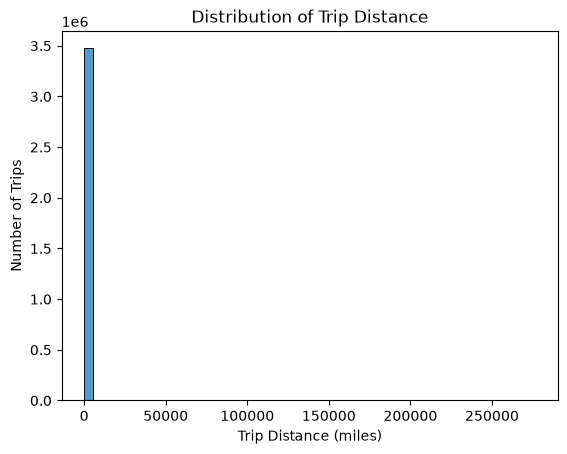

In [59]:
sns.histplot(clean_df['trip_distance'],bins=50)
plt.title('Distribution of Trip Distance')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Number of Trips')
plt.show()

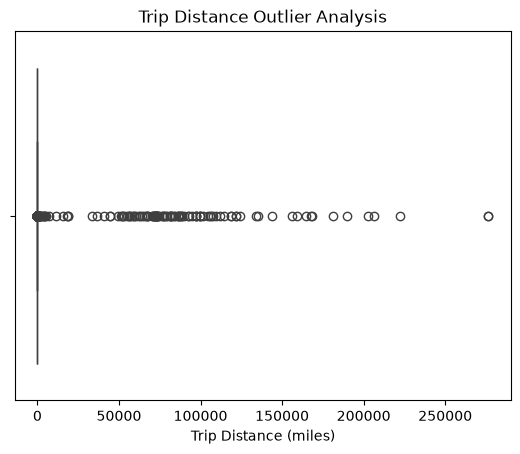

In [60]:
sns.boxplot(x=clean_df['trip_distance'])
plt.title('Trip Distance Outlier Analysis')
plt.xlabel('Trip Distance (miles)')
plt.show()

# Trip Duration Analysis

In [61]:
clean_df['trip_duration_minutes'].describe()

count    3.473175e+06
mean     1.504188e+01
std      2.713346e+01
min      1.666667e-02
25%      7.283333e+00
50%      1.170000e+01
75%      1.835000e+01
max      5.626317e+03
Name: trip_duration_minutes, dtype: float64

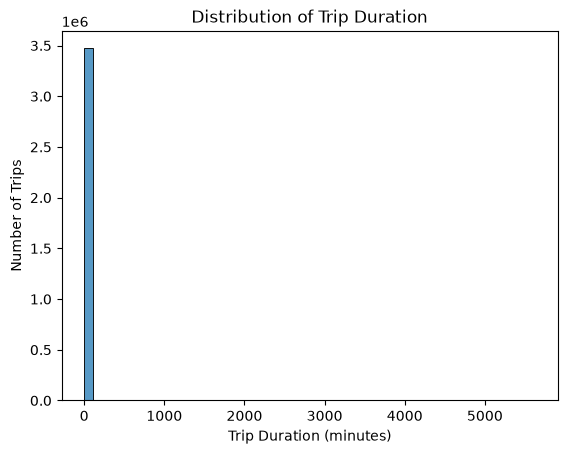

In [62]:
sns.histplot(clean_df['trip_duration_minutes'],bins=50)
plt.title('Distribution of Trip Duration')
plt.xlabel('Trip Duration (minutes)')
plt.ylabel('Number of Trips')
plt.show()

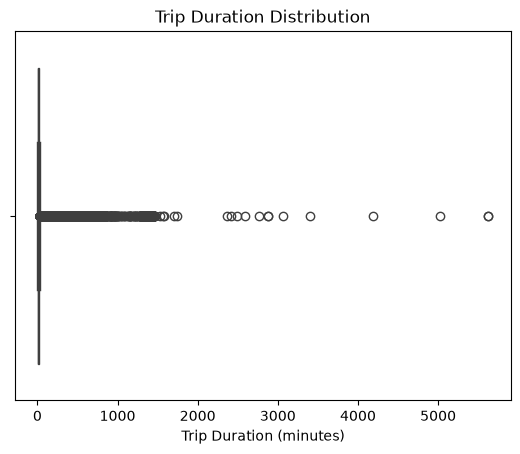

In [63]:
sns.boxplot(x=clean_df['trip_duration_minutes'])
plt.title('Trip Duration Distribution')
plt.xlabel('Trip Duration (minutes)')
plt.show()

# Distance vs Duration

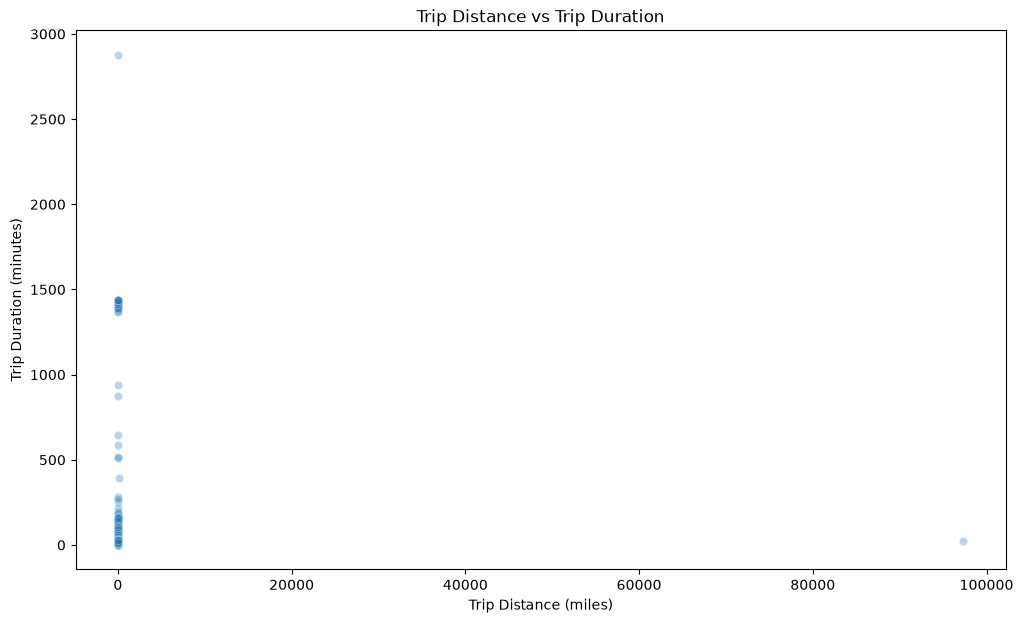

In [64]:
sample_df = clean_df.sample(min(100000, len(clean_df)),random_state=42)
plt.figure(figsize=(12, 7))
sns.scatterplot(data=sample_df,x='trip_distance',y='trip_duration_minutes',alpha=0.3)
plt.title('Trip Distance vs Trip Duration')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Trip Duration (minutes)')
plt.show()

# Passenger Analysis

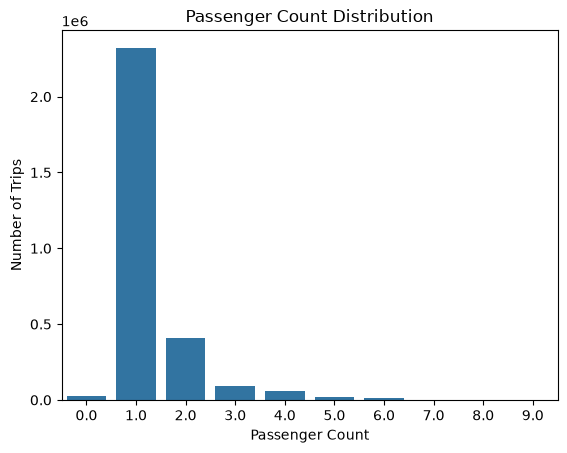

In [65]:
sns.countplot(data=clean_df,x='passenger_count')
plt.title('Passenger Count Distribution')
plt.xlabel('Passenger Count')
plt.ylabel('Number of Trips')
plt.show()

In [66]:
most_common_passenger = (clean_df['passenger_count'].mode()[0])
print("Most common passenger count:",most_common_passenger)

Most common passenger count: 1.0


In [67]:
one_passenger_percentage = ((clean_df['passenger_count'] == 1).mean() * 100)
print(f"One-passenger trips: {one_passenger_percentage:.2f}%")

One-passenger trips: 66.83%


# Passenger vs Distance

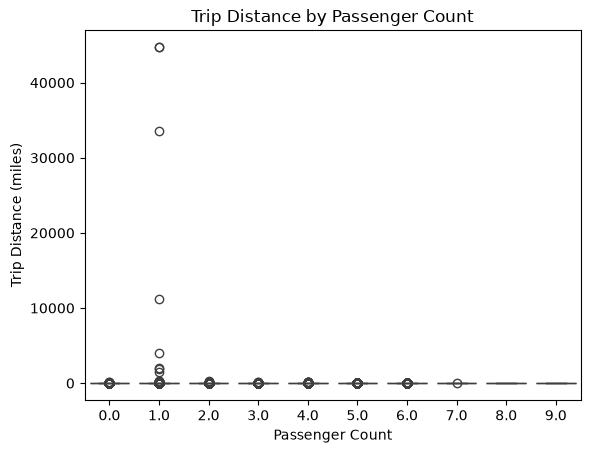

In [68]:
sns.boxplot(data=clean_df,x='passenger_count',y='trip_distance')
plt.title('Trip Distance by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Trip Distance (miles)')
plt.show()

# Passenger vs Duration

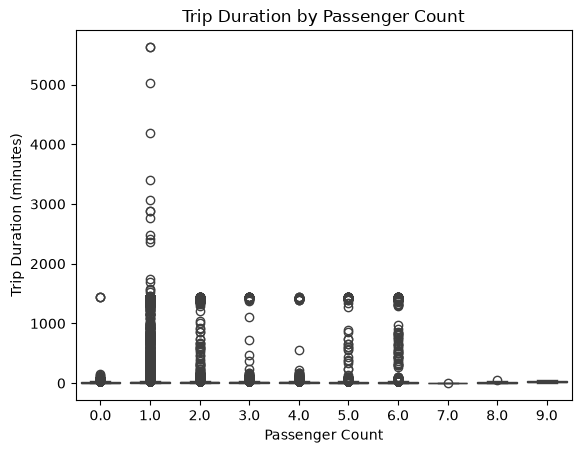

In [58]:
sns.boxplot(data=clean_df,x='passenger_count',y='trip_duration_minutes')
plt.title('Trip Duration by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Trip Duration (minutes)')
plt.show()

# Pickup Locations

In [69]:
top_pickups = (clean_df['PULocationID'].value_counts().head(10))
top_pickups

PULocationID
161    169859
237    163536
236    155476
132    146099
230    125781
186    119086
162    117875
142    110514
239     96564
163     95865
Name: count, dtype: int64

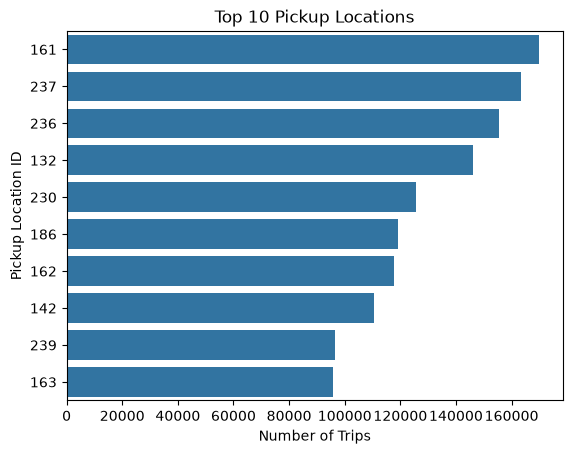

In [70]:
sns.barplot(x=top_pickups.values,y=top_pickups.index.astype(str))
plt.title('Top 10 Pickup Locations')
plt.xlabel('Number of Trips')
plt.ylabel('Pickup Location ID')
plt.show()

# Drop-off Locations

In [71]:
top_dropoffs = (clean_df['DOLocationID'].value_counts().head(10))
top_dropoffs

DOLocationID
236    161292
237    149876
161    131195
230    108138
170    100019
142     98948
239     97517
162     93763
141     92623
68      89193
Name: count, dtype: int64

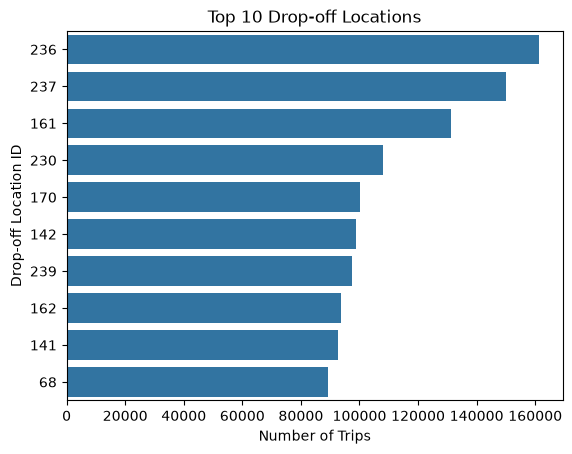

In [72]:
sns.barplot(x=top_dropoffs.values,y=top_dropoffs.index.astype(str))
plt.title('Top 10 Drop-off Locations')
plt.xlabel('Number of Trips')
plt.ylabel('Drop-off Location ID')
plt.show()

# Most Common Routes

In [73]:
top_routes = (clean_df['route'].value_counts().head(20))
top_routes

route
237 → 236    24820
236 → 237    21822
236 → 236    18203
237 → 237    17420
161 → 237    11455
237 → 161    10164
161 → 236     9834
239 → 238     9595
142 → 239     9135
239 → 142     8841
141 → 236     8814
186 → 230     8546
236 → 141     8240
236 → 161     8028
237 → 162     7878
237 → 141     7852
238 → 239     7851
236 → 239     7682
132 → 132     7594
161 → 161     7485
Name: count, dtype: int64

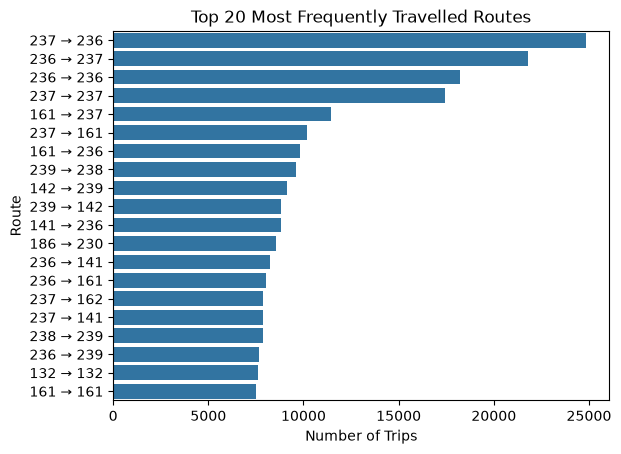

In [74]:
sns.barplot(x=top_routes.values,y=top_routes.index)
plt.title('Top 20 Most Frequently Travelled Routes')
plt.xlabel('Number of Trips')
plt.ylabel('Route')
plt.show()

# Route Performance Analysis

In [75]:
route_summary = (clean_df.groupby('route').agg(trip_count=('route', 'size'),avg_distance=('trip_distance', 'mean'),avg_duration=('trip_duration_minutes', 'mean')).reset_index())

In [76]:
route_analysis = route_summary[route_summary['trip_count'] >= 100].copy()

In [78]:
route_analysis.sort_values('avg_distance',ascending=False).head(10)

,route,trip_count,avg_distance,avg_duration
16113,224 → 233,149,1854.513624,8.997204
24775,42 → 238,154,1094.233961,16.734632
24781,42 → 243,102,1073.538529,16.302288
18825,239 → 13,238,573.611134,23.859244
24596,41 → 243,127,570.777165,18.489764
24533,41 → 161,169,517.608698,22.320118
10000,170 → 41,169,445.461361,22.900690
25777,50 → 186,534,381.276199,10.794819
22358,263 → 48,561,370.520517,18.854753
31747,90 → 4,285,352.002035,14.490351


In [79]:
route_analysis.sort_values('avg_duration',ascending=False).head(10)

,route,trip_count,avg_distance,avg_duration
3617,132 → 1,149,36.238255,69.189821
19688,246 → 132,211,17.975118,56.986967
31010,87 → 132,238,20.424748,55.277591
24873,43 → 132,214,17.913879,54.877181
7585,158 → 132,222,21.453243,54.759159
27854,68 → 132,499,17.634088,53.955210
3823,132 → 50,668,19.193533,53.841791
3662,132 → 143,1101,20.029046,53.807826
5732,143 → 132,173,20.158382,53.182177
3815,132 → 43,412,18.521748,52.509223


# Payment Analysis

In [80]:
payment_counts = (clean_df['payment_type'].value_counts())
payment_counts

payment_type
1    2443161
0     539930
2     389894
4      76473
3      23716
5          1
Name: count, dtype: int64

In [81]:
payment_percentage = (payment_counts /payment_counts.sum() * 100)
payment_percentage

payment_type
1    70.343734
0    15.545718
2    11.225867
4     2.201818
3     0.682833
5     0.000029
Name: count, dtype: float64

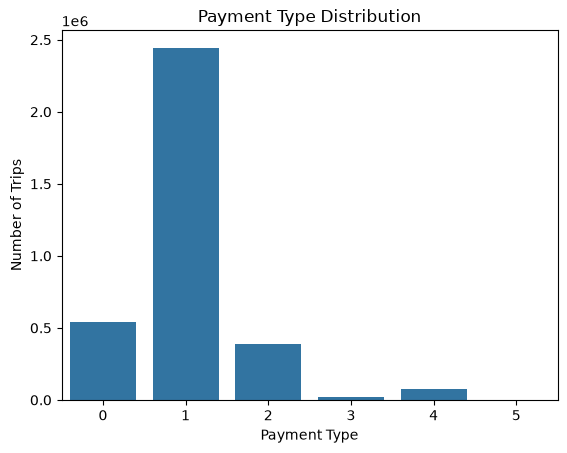

In [82]:
sns.countplot(data=clean_df,x='payment_type')
plt.title('Payment Type Distribution')
plt.xlabel('Payment Type')
plt.ylabel('Number of Trips')
plt.show()

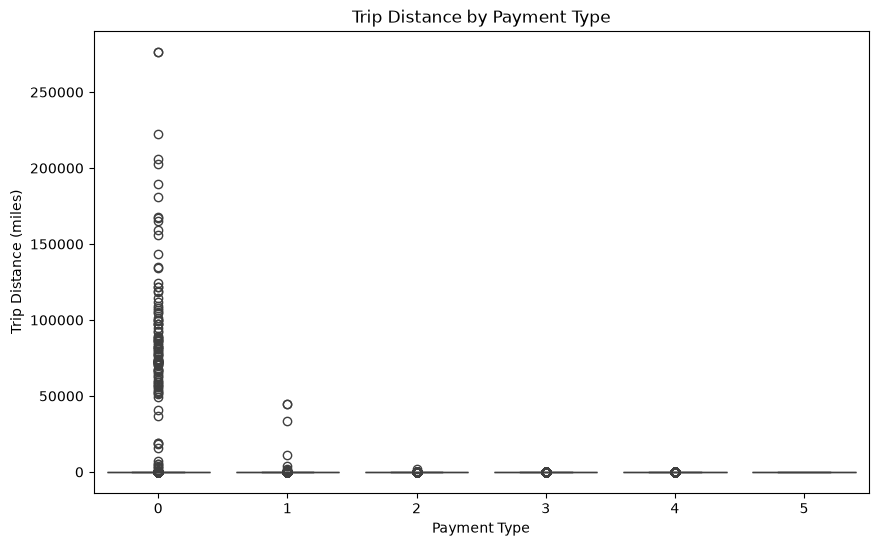

In [83]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=clean_df,x='payment_type',y='trip_distance')
plt.title('Trip Distance by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Trip Distance (miles)')
plt.show()

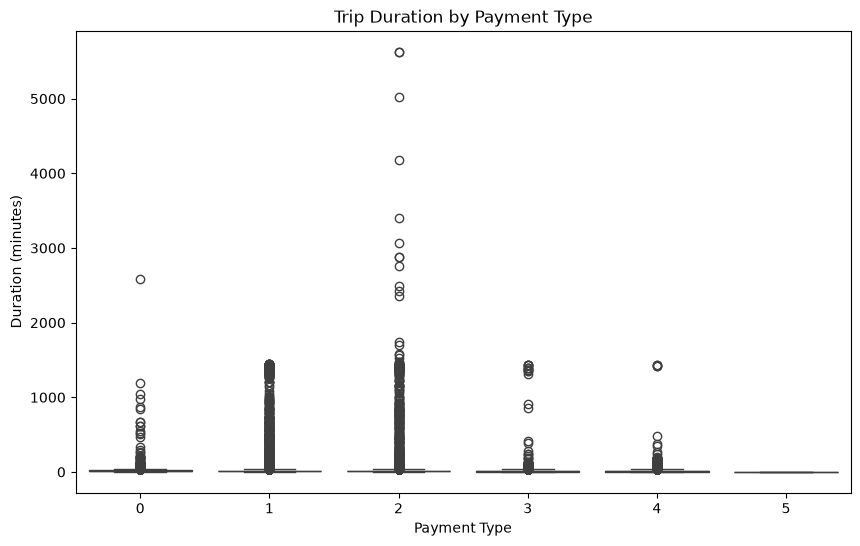

In [84]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=clean_df,x='payment_type',y='trip_duration_minutes')
plt.title('Trip Duration by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Duration (minutes)')
plt.show()

# Vendor Analysis

In [85]:
vendor_counts = (clean_df['VendorID'].value_counts())
vendor_counts

VendorID
2    2719784
1     753025
6        366
Name: count, dtype: int64

In [86]:
vendor_percentage = (vendor_counts /vendor_counts.sum() * 100)
vendor_percentage

VendorID
2    78.308291
1    21.681171
6     0.010538
Name: count, dtype: float64

In [87]:
vendor_distance = (clean_df.groupby('VendorID')['trip_distance'].agg(['count', 'mean', 'median']))
vendor_distance

,count,mean,median
VendorID,,,
1,753025,3.200715,1.700
2,2719784,6.592768,1.670
6,366,9.520847,8.965


In [88]:
vendor_duration = (clean_df.groupby('VendorID')['trip_duration_minutes'].agg(['count', 'mean', 'median']))
vendor_duration

,count,mean,median
VendorID,,,
1,753025,15.711980,11.950000
2,2719784,14.852726,11.633333
6,366,41.925774,59.716667


# Rate-Code Analysis

In [89]:
rate_counts = (clean_df['RatecodeID'].value_counts())
rate_counts

RatecodeID
1.0     2754888
2.0       94398
99.0      41789
5.0       26450
3.0        8622
4.0        7091
6.0           7
Name: count, dtype: int64

In [90]:
rate_percentage = (rate_counts /rate_counts.sum() * 100)
rate_percentage

RatecodeID
1.0     93.919465
2.0      3.218211
99.0     1.424668
5.0      0.901732
3.0      0.293941
4.0      0.241746
6.0      0.000239
Name: count, dtype: float64

In [91]:
clean_df.groupby('RatecodeID')['trip_distance'].agg(['count', 'mean', 'median'])

,count,mean,median
RatecodeID,,,
1.0,2754888,2.496485,1.54
2.0,94398,17.182594,17.83
3.0,8622,14.347970,16.84
4.0,7091,20.964803,17.98
5.0,26450,5.569016,0.17
6.0,7,0.457143,0.20
99.0,41789,10.847871,6.60


In [92]:
clean_df.groupby('RatecodeID')['trip_duration_minutes'].agg(['count', 'mean', 'median'])

,count,mean,median
RatecodeID,,,
1.0,2754888,13.411958,10.816667
2.0,94398,43.944610,43.116667
3.0,8622,30.248846,31.350000
4.0,7091,40.313914,34.350000
5.0,26450,15.266279,1.783333
6.0,7,0.733333,0.133333
99.0,41789,45.472413,41.016667


# Store-and-Forward Analysis

In [93]:
store_forward = (clean_df['store_and_fwd_flag'].value_counts())
store_forward

store_and_fwd_flag
N    2925913
Y       7332
Name: count, dtype: int64

In [94]:
store_forward_percentage = (store_forward /store_forward.sum() * 100)
store_forward_percentage

store_and_fwd_flag
N    99.750038
Y     0.249962
Name: count, dtype: float64

In [95]:
clean_df.groupby('store_and_fwd_flag')['trip_distance'].agg(['count', 'mean', 'median'])

,count,mean,median
store_and_fwd_flag,,,
N,2925913,3.196407,1.6
Y,7332,2.744790,1.5


In [96]:
clean_df.groupby('store_and_fwd_flag')['trip_duration_minutes'].agg(['count', 'mean', 'median'])

,count,mean,median
store_and_fwd_flag,,,
N,2925913,14.985935,11.25
Y,7332,13.625084,10.90


# Correlation Analysis

In [97]:
correlation_columns = [
    'passenger_count',
    'trip_distance',
    'trip_duration_minutes',
    'average_speed_mph'
]
correlation_matrix = (clean_df[correlation_columns].corr())
correlation_matrix

,passenger_count,trip_distance,trip_duration_minutes,average_speed_mph
passenger_count,1.000000,0.003600,0.023168,0.000398
trip_distance,0.003600,1.000000,0.003011,0.785068
trip_duration_minutes,0.023168,0.003011,1.000000,-0.000339
average_speed_mph,0.000398,0.785068,-0.000339,1.000000


In [98]:
correlation_columns = [
    'passenger_count',
    'trip_distance',
    'trip_duration_minutes',
    'average_speed_mph'
]
correlation_matrix = (clean_df[correlation_columns].corr())
correlation_matrix

,passenger_count,trip_distance,trip_duration_minutes,average_speed_mph
passenger_count,1.000000,0.003600,0.023168,0.000398
trip_distance,0.003600,1.000000,0.003011,0.785068
trip_duration_minutes,0.023168,0.003011,1.000000,-0.000339
average_speed_mph,0.000398,0.785068,-0.000339,1.000000


# Advanced Analysis

In [100]:
clean_df['distance_band'] = pd.qcut(clean_df['trip_distance'],q=4,labels=['Q1 - Shortest','Q2','Q3','Q4 - Longest'],duplicates='drop')

In [101]:
clean_df.groupby('distance_band',observed=True).agg(
    trip_count=('trip_distance', 'size'),
    avg_duration=('trip_duration_minutes', 'mean'),
    avg_speed=('average_speed_mph', 'mean'),
    avg_passengers=('passenger_count', 'mean'))

,trip_count,avg_duration,avg_speed,avg_passengers
distance_band,,,,
Q1 - Shortest,873343,6.904583,7.212541,1.278000
Q2,865981,10.221816,8.982681,1.288707
Q3,869639,14.961416,10.223164,1.295265
Q4 - Longest,864212,28.176033,76.851136,1.332560


In [102]:
clean_df['period'] = np.where(clean_df['pickup_hour'].between(7, 9) | clean_df['pickup_hour'].between(16, 19),'Peak','Off-Peak')

In [123]:
clean_df.groupby('period').agg(
    trip_count=('period', 'size'),
    avg_distance=('trip_distance', 'mean'),
    avg_duration=('trip_duration_minutes', 'mean'),
    avg_speed=('average_speed_mph', 'mean')
)

,trip_count,avg_distance,avg_duration,avg_speed
period,,,,
Off-Peak,2127748,5.615588,14.874134,27.422401
Peak,1345427,6.240437,15.307152,23.067793


In [103]:
route_counts = (clean_df['route'].value_counts())
route_share = (route_counts /route_counts.sum() * 100)
top_20_route_share = route_share.head(20).sum()
print(
    f"Top 20 routes account for "
    f"{top_20_route_share:.2f}% of all trips.")

Top 20 routes account for 6.37% of all trips.


In [104]:
clean_df['average_speed_mph'].describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])

count    3.473175e+06
mean     2.573553e+01
std      3.873889e+03
min      0.000000e+00
1%       0.000000e+00
5%       3.813285e+00
25%      7.209011e+00
50%      9.517748e+00
75%      1.293292e+01
95%      2.506782e+01
99%      3.554229e+01
max      3.722497e+06
Name: average_speed_mph, dtype: float64

In [105]:
high_speed = clean_df[clean_df['average_speed_mph'] > 60]
high_speed[['trip_distance',
        'trip_duration_minutes',
        'average_speed_mph']].head(20)

,trip_distance,trip_duration_minutes,average_speed_mph
4324,12.89,8.666667,89.238462
7872,2.20,0.266667,495.000000
8040,3.00,0.433333,415.384615
10040,97.42,90.466667,64.611643
12954,6.10,1.016667,360.000000
13736,3.40,0.400000,510.000000
16610,4.00,0.900000,266.666667
20603,1.90,0.550000,207.272727
20740,0.11,0.033333,198.000000
21868,0.80,0.116667,411.428571


# Create The KPI Summary

In [106]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Trips',
        'Average Trip Distance',
        'Median Trip Distance',
        'Average Trip Duration',
        'Median Trip Duration',
        'Maximum Trip Distance',
        'Maximum Trip Duration',
        'Average Speed',
        'Most Common Passenger Count',
        'Busiest Pickup Hour',
        'Busiest Day',
        'Most Common Payment Type',
        'Most Common Pickup Location',
        'Most Common Drop-off Location',
        'Most Common Route'
    ],

    'Value': [
        len(clean_df),
        clean_df['trip_distance'].mean(),
        clean_df['trip_distance'].median(),
        clean_df['trip_duration_minutes'].mean(),
        clean_df['trip_duration_minutes'].median(),
        clean_df['trip_distance'].max(),
        clean_df['trip_duration_minutes'].max(),
        clean_df['average_speed_mph'].mean(),
        clean_df['passenger_count'].mode()[0],
        clean_df['pickup_hour'].value_counts().idxmax(),
        clean_df['day_of_week'].value_counts().idxmax(),
        clean_df['payment_type'].value_counts().idxmax(),
        clean_df['PULocationID'].value_counts().idxmax(),
        clean_df['DOLocationID'].value_counts().idxmax(),
        clean_df['route'].value_counts().idxmax()
    ]
})

kpi_summary

,KPI,Value
0,Total Trips,3473175
1,Average Trip Distance,5.85764
2,Median Trip Distance,1.67
3,Average Trip Duration,15.041875
4,Median Trip Duration,11.7
5,Maximum Trip Distance,276423.57
6,Maximum Trip Duration,5626.316667
7,Average Speed,25.735527
8,Most Common Passenger Count,1.0
9,Busiest Pickup Hour,18


# Final Business Questions

# Business Questions & Answers

## 1. When is taxi demand highest?

Taxi demand is highest during hour 18:00

## 2. When is taxi demand lowest?

Taxi demand is lowest during hour 4:00

## 3. How does weekday demand compare with weekend demand?

Weekday trips : 2,594,572

Weekend trips : 878,603

Weekday share : 74.70%

Weekend share : 25.30%

Weekdays account for 74.70% of trips, compared with 25.30% on weekends. Therefore, taxi demand is higher on weekdays.

## 4. What does a typical taxi trip look like?

Average distance : 5.86 miles

Median distance  : 1.67 miles

Average duration : 15.04 minutes

Median duration  : 11.70 minutes

A typical taxi trip covers approximately 1.67 miles and lasts approximately 11.70 minutes. The median provides a better representation of a typical trip because extreme trips can influence the mean.


## 5. What are the most common pickup locations?

The most common pickup location is Taxi Zone ID 161, with 169,859 trips.


## 6. What are the most common drop-off locations?

The most common drop-off location is Taxi Zone ID 236, with 161,292 trips.

## 7. What are the most frequently travelled routes?

The most frequently travelled route is 237 → 236, with 24,820 trips.

## 8. Are longer trips generally associated with longer durations?

Correlation between trip distance and trip duration: 0.0030

The data shows a weak positive relationship between trip distance and trip duration.

## 9. What passenger-count patterns can be observed?

Most common passenger count: 1.0

Percentage of one-passenger trips: 66.83%

The most common passenger count is 1.0. One-passenger trips account for 66.83% of all analyzed trips, indicating that single-passenger journeys represent a substantial/share of taxi activity.


## 10. Which payment types are most common?

Most common payment type: 1

## 11. How do trip characteristics vary across vendors?

Vendor observations:

Vendor 1.0: 21.68% of trips, average distance 3.20 miles, average duration 15.71 minutes.

Vendor 2.0: 78.31% of trips, average distance 6.59 miles, average duration 14.85 minutes.

Vendor 6.0: 0.01% of trips, average distance 9.52 miles, average duration 41.93 minutes.
## 12. Which rate codes are most frequently used?

Most frequently used rate code: 1.0




## 13. What unusual or potentially problematic records exist?

Negative-duration records: 0

Zero-duration records: 0

Zero/negative-distance records: 90201

99th percentile duration: 58.92 minutes

Trips above 99th percentile: 34,725

99th percentile distance: 19.51 miles

Trips above 99th percentile: 34,624

99th percentile speed: 35.54 mph

Trips above 99th percentile: 34,732

## 14. What are the major limitations?

## Major Limitations

1. **Limited time period:** The dataset covers January 2025 only, so the findings represent one month and may not generalize to the entire year.

2. **No revenue information:** The dataset does not contain fare amount, tip amount, total trip revenue or profit. Therefore, actual revenue or profitability cannot be calculated.

3. **No customer information:** Customer IDs are not available, so individual customer behavior, customer retention or customer spending cannot be analyzed.

4. **No driver information:** Driver IDs and driver-level performance measures are not available.

5. **Location IDs rather than neighborhood names:** `PULocationID` and `DOLocationID` represent TLC Taxi Zone IDs. Without a separate Taxi Zone lookup table, these should be interpreted as location IDs rather than neighborhood names.

6. **Outliers:** Extremely long, short, fast or slow trips may represent either legitimate unusual trips or data-quality problems. Therefore, outliers require investigation rather than automatic deletion.

7. **Correlation limitations:** Correlation can identify relationships between numerical variables but does not establish causation.

8. **Small groups:** Rare payment types, rate codes, vendors or routes should be interpreted cautiously because conclusions based on very small groups may not be reliable.

9. **Vendor comparisons:** Differences between vendors describe observed characteristics in the dataset and should not automatically be interpreted as differences in vendor performance.


# Final Conclusion

This project analyzed NYC Yellow Taxi trip activity for January 2025 using Python, NumPy, Pandas, Matplotlib and Seaborn.

The analysis examined taxi demand patterns, trip distance, trip duration, passenger behavior, pickup and drop-off locations, routes, payment types, vendors, rate codes and operational characteristics.

The results provide evidence-based insights into when taxi demand is highest, where trips are concentrated, how trip distance relates to duration, and how trip characteristics vary across different operational categories.

The analysis also identified data-quality issues and unusual observations that should be considered when interpreting the results.

Overall, the project demonstrates an end-to-end data-analysis workflow from raw trip-level data through data-quality assessment, cleaning, feature engineering, statistical analysis, visualization and business interpretation.